# Análise do Suporte de Cliente da Agência AtendeBem

# Objetivos
- Realizar uma **Análise Exploratória** para responder perguntas específicas da área de negócio;
- Construir um **Relatório Técnico** contendo ações para melhorar a experiência do cliente.

In [1]:
# Imports
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import sqrt
from scipy.stats import beta, t, pearsonr
from matplotlib.lines import Line2D

# adiciona diretório raiz do projeto ao sys.path
sys.path.insert(0, str(Path.cwd().parent))

# configurações gerais
pd.set_option('display.max_rows', None)
sns.set_theme(style='whitegrid', palette='pastel')
%matplotlib inline

# 1. Carga dos Dados

In [2]:
data_path = Path.cwd().parent / 'data' / 'area-de-atendimento.xlsx'

raw_data = pd.read_excel(
    data_path,
    engine='openpyxl'
)

print(f"Dataset carregado de: {data_path}")
print("\n========= Dimensões do Dataset =========\n")
print(f"Número de Linhas: {raw_data.shape[0]}")
print(f"Número de Colunas: {raw_data.shape[1]}")
raw_data.head()

Dataset carregado de: c:\Users\jooar\ds\LABS\data-analisys-labs\data-analisys-labs\projects\customer-support\data\area-de-atendimento.xlsx

========= Dimensões do Dataset =========

Número de Linhas: 1000
Número de Colunas: 10


,ID_Cliente,Tempo_Espera,Tempo_Resolucao,Satisfacao_Cliente,Canal_Atendimento,Tipo_Problema,Feedback_Sentimento,Media_NPS,Qtd_Reclamacoes,Problema_Solucionado
0,1,11,22,6,E-mail,Cobrança,Positivo,61,1,Sim
1,2,5,10,9,E-mail,Atendimento Ruim,Neutro,88,0,Não
2,3,21,41,3,Chat,Produto Defeituoso,Neutro,28,2,Sim
3,4,13,27,6,Redes Sociais,Produto Defeituoso,Negativo,55,1,Sim
4,5,16,34,4,Redes Sociais,Produto Defeituoso,Negativo,37,2,Não


## 1.1 Visão Geral do Dataset

**Descrição**: conjunto de dados de atendimentos a clientes, com informações sobre espera, resolução, satisfação, canal, problema relatado, sentimento, NPS, reclamações e solução.

| Variável | Tipo sugerido | Descrição |
|---|---|---|
| `ID_Cliente` | Identificador | Código que identifica o cliente. |
| `Tempo_Espera` | Numérico inteiro | Tempo, em minutos, que o cliente aguardou até ser atendido. |
| `Tempo_Resolucao` | Numérico inteiro | Tempo, em minutos, gasto pelo atendente durante o atendimento para tratar o problema. |
| `Satisfacao_Cliente` | Numérico | Nota de satisfação atribuída pelo cliente, de 0 a 10. |
| `Canal_Atendimento` | Categórico | Canal utilizado no atendimento, como telefone, chat, e-mail, WhatsApp ou redes sociais. |
| `Tipo_Problema` | Categórico | Tipo de questão relatada, como dúvida, produto defeituoso, atendimento ruim ou cobrança. |
| `Feedback_Sentimento` | Categórico | Sentimento associado ao feedback do cliente, como positivo, neutro ou negativo. |
| `Media_NPS` | Numérico | Valor médio de NPS associado ao registro. A escala e o método de cálculo não foram especificados. |
| `Qtd_Reclamacoes` | Numérico inteiro | Quantidade de reclamações registrada para o cliente ou atendimento. |
| `Problema_Solucionado` | Binário/categórico | Indica se o problema foi solucionado (`Sim` ou `Não`). |

Antes de seguirmos com as análises é importante fazer uma verificação na qualidade dos dados (**Sanity Check**), vamos verificar:
- a presença de dados duplicados;
- verificar se há dados nulos ou inválidos;
- a presença de outliers.


In [3]:
# informações gerais sobre o dataset
print("========= Informações do Dataset =========\n")
raw_data.info()

print("\n========= Dados Duplicados =========")
dados_duplicados = raw_data.duplicated().sum()
print(f"Número de linhas duplicadas: {dados_duplicados}")

========= Informações do Dataset =========

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   ID_Cliente            1000 non-null   int64
 1   Tempo_Espera          1000 non-null   int64
 2   Tempo_Resolucao       1000 non-null   int64
 3   Satisfacao_Cliente    1000 non-null   int64
 4   Canal_Atendimento     1000 non-null   str  
 5   Tipo_Problema         1000 non-null   str  
 6   Feedback_Sentimento   1000 non-null   str  
 7   Media_NPS             1000 non-null   int64
 8   Qtd_Reclamacoes       1000 non-null   int64
 9   Problema_Solucionado  1000 non-null   str  
dtypes: int64(6), str(4)
memory usage: 78.3 KB

========= Dados Duplicados =========
Número de linhas duplicadas: 0


**Não foram identificados valores nulos ou duplicados na base**. Seguindo na investigação, será verificado se há valores inválidos e outliers na base.

In [4]:
#dropando a variável ID_Cliente, pois não é relevante para a análise
new_data = raw_data.drop(columns=['ID_Cliente'])

# separando as variáveis numéricas e categóricas
num_vars = [col for col in new_data.columns if new_data[col].dtype == 'int64']
cat_vars = [col for col in new_data.columns if new_data[col].dtype == 'str']

print("=========== Granularidade das Variáveis Categóricas ===========\n")
print(new_data[cat_vars].nunique())
print('\n========= Valores Únicos das Variáveis Categóricas =========\n')
for var in cat_vars:
    print(f"{var}: {new_data[var].unique().tolist()}")

print("\n=========== Estatísticas Descritivas das Variáveis Numéricas ===========\n")
print(new_data[num_vars].describe())


print("\n=========== Percentual de Outliers nas Variáveis Numéricas ===========\n")
for var in num_vars:
    Q1 = new_data[var].quantile(0.25)
    Q3 = new_data[var].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = new_data[(new_data[var] < lower_bound) | (new_data[var] > upper_bound)]
    outlier_percentage = (len(outliers) / len(new_data)) * 100
    print(f"{var}: {outlier_percentage:.2f}% de outliers")

=========== Granularidade das Variáveis Categóricas ===========

Canal_Atendimento       5
Tipo_Problema           4
Feedback_Sentimento     3
Problema_Solucionado    2
dtype: int64

========= Valores Únicos das Variáveis Categóricas =========

Canal_Atendimento: ['E-mail', 'Chat', 'Redes Sociais', 'Telefone', 'WhatsApp']
Tipo_Problema: ['Cobrança', 'Atendimento Ruim', 'Produto Defeituoso', 'Dúvida']
Feedback_Sentimento: ['Positivo', 'Neutro', 'Negativo']
Problema_Solucionado: ['Sim', 'Não']

=========== Estatísticas Descritivas das Variáveis Numéricas ===========

       Tempo_Espera  Tempo_Resolucao  Satisfacao_Cliente    Media_NPS  \
count   1000.000000      1000.000000         1000.000000  1000.000000   
mean      13.356000        27.669000            5.572000    55.016000   
std        8.781137        17.102747            2.978538    29.698076   
min        1.000000         5.000000            1.000000     0.000000   
25%        5.000000        11.000000            3.000000    28.

Após a verificação, **não foram identificados valores inválidos ou inconsistências** aparentes nas variáveis analisadas. A variável binária apresentou duas categorias distintas, conforme esperado, enquanto **as demais variáveis categóricas apresentaram valores coerentes com seus respectivos domínios**, sem indícios de erros de digitação ou classificações inadequadas.

Em relação as **variáveis numéricas**, todas elas apresentaram uma faixa de valores plausíveis com os seus respectivos domínios. Além disso, **não foram identificados outliers na base.**

A classificação das variáveis é a seguinte:
- **Qualitativas Nominais**: `Canal_Atendimento` e `Tipo_Problema`.
- **Qualitativas Ordinais**: `Feedback_Sentimento`.
- **Qualitativa Binária**: `Problema_Solucionado`.
- **Quantitativa Discreta**: `Qtd_Reclamacoes`, `Tempo_Espera`, `Tempo_Resolucao`, `Satisfacao_Cliente` e `Media_NPS`

# 2. Q&A - respondendo perguntas de negócio
Durantes uma reunião algumas perguntas foram levantadas e será nossa responsabilidade respondê-las. Para cada pergunta, vamos dedicar uma subseção a seguir para explorar os dados e respondê-las da melhor maneira.

### Q1 - O tempo de atendimento tem um impacto significativo na satisfação do cliente? Existe uma relação clara entre tempo de atendimento e Net Promoter Score (NPS)?

Os resultados indicam **associações lineares negativas muito fortes** entre o tempo de atendimento e as duas variáveis, NPS e Satisfação do Cliente:
- **Satisfação**: r = -0.86, p-valor = 1.166e-299
- **NPS**: r = -0.88, p-valor = 3.36e-322

Como ambos os p-valores são muito menores que 0.05, há evidências estatísticas de que as correlações populacionais observadas são diferentes de zero. Em termos práticos, podemos assumir que **atendimentos mais longos tendem a estar associados a avaliações menores**.

Para avaliar se o tempo de atendimento está relacionado à satisfação do cliente e ao NPS, **será criada uma variável que represente o tempo total gasto em cada atendimento**, somando o tempo de espera ao tempo de resolução.

**Cálculo do tempo de atendimento:**
$$
\text{Tempo de atendimento} = \text{Tempo de espera} + \text{Tempo de resolução}
$$

Em seguida, será analisada a relação entre o tempo de atendimento e cada indicador — satisfação e NPS — por meio de **gráficos de dispersão**. Como são variáveis quantitativas, os gráficos **mostram a distribuição conjunta dos valores** e permitem observar o formato da nuvem de pontos: se há uma tendência crescente ou decrescente, se a relação parece linear ou se não existe um padrão evidente.

O gráfico permite identificar visualmente uma possível associação, mas **não quantifica sua intensidade**. Para complementar a análise, será calculada a correlação de Pearson, que mede a **direção e a intensidade da relação linear** entre duas variáveis quantitativas.

$$
r_{XY} =
\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{
\sum_{i=1}^{n}(x_i-\bar{x})^2
\sum_{i=1}^{n}(y_i-\bar{y})^2
}}
$$

Em que:

- $r_{XY}$ é o coeficiente de correlação de Pearson entre as variáveis $X$ e $Y$;
- $x_i$ e $y_i$ são os valores observados de $X$ e $Y$ na observação $i$;
- $\bar{x}$ e $\bar{y}$ são as médias das variáveis $X$ e $Y$;
- $n$ é o número de observações;
- $i$ identifica cada observação, de 1 a $n$.

O coeficiente de Pearson varia de −1 a +1. Valores próximos de +1 indicam associação linear positiva; valores próximos de −1 indicam associação negativa; e valores próximos de 0 indicam pouca ou nenhuma associação linear. 

Como referência geral, valores absolutos abaixo de 0,3 podem ser descritos como fracos, de 0,3 a 0,7 como moderados e acima de 0,7 como fortes. Esses limites são orientativos e devem ser interpretados no contexto dos dados.

> No código, utilizei o pacote `pearsonr` para calcular as correlações entre o tempo de atendimento e as demais variáveis. Ele também realiza o **teste estatístico** tradicionalmente associado ao coeficiente de correlação de Pearson, o **teste t de Student (bilateral) para significância da correlação**. Ele permite investigar se a correlação linear observada em uma amostra fornece **evidências estatísticas de que existe uma correlação linear diferente de zero na população**.

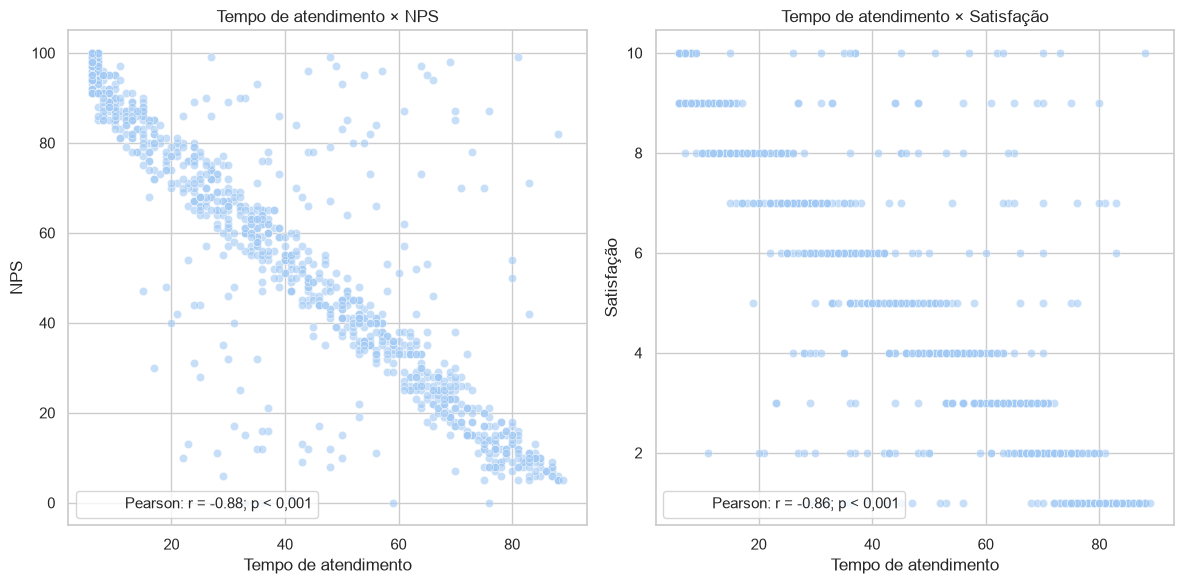

-------------- Teste de Correlação de Pearson --------------
Satisfação: r = -0.86, p-valor = 1.166e-299
NPS: r = -0.88, p-valor = 3.36e-322


In [5]:
df =new_data.copy()

# Calcular o tempo total de atendimento
df["Tempo_Atendimento"] = df["Tempo_Espera"] + df["Tempo_Resolucao"]

# Calcular o coeficiente de Pearson e o p-valor
r_nps, p_nps = pearsonr(
    df["Tempo_Atendimento"],
    df["Media_NPS"]
)


r_satisfacao, p_satisfacao = pearsonr(
    df["Tempo_Atendimento"],
    df["Satisfacao_Cliente"]
)

# Formatar o p-valor para a legenda
def formatar_p_valor(p):
    return "p < 0,001" if p < 0.001 else f"p = {p:.3f}".replace(".", ",")

# Criar os subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Gráfico de dispersão: tempo de atendimento × NPS
sns.scatterplot(
    data=df,
    x="Tempo_Atendimento",
    y="Media_NPS",
    alpha=0.6,
    ax=axes[0]
)
axes[0].set_title("Tempo de atendimento × NPS")
axes[0].set_xlabel("Tempo de atendimento")
axes[0].set_ylabel("NPS")

legenda_nps = Line2D(
    [], [],
    linestyle="none",
    label=f"Pearson: r = {r_nps:.2f}; {formatar_p_valor(p_nps)}"
)
axes[0].legend(handles=[legenda_nps], loc="lower left")

# Gráfico de dispersão: tempo de atendimento × satisfação
sns.scatterplot(
    data=df,
    x="Tempo_Atendimento",
    y="Satisfacao_Cliente",
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title("Tempo de atendimento × Satisfação")
axes[1].set_xlabel("Tempo de atendimento")
axes[1].set_ylabel("Satisfação")

legenda_satisfacao = Line2D(
    [], [],
    linestyle="none",
    label=(
        f"Pearson: r = {r_satisfacao:.2f}; "
        f"{formatar_p_valor(p_satisfacao)}"
    )
)
axes[1].legend(handles=[legenda_satisfacao], loc="lower left")

plt.tight_layout()
plt.show()

print("-------------- Teste de Correlação de Pearson --------------")
print(f"Satisfação: r = {r_satisfacao:.2f}, p-valor = {p_satisfacao:.4g}")
print(f"NPS: r = {r_nps:.2f}, p-valor = {p_nps:.4g}")

### Q2 - Quais fatores afetam diretamente o NPS? Será que há relação entre tempo de espera, quantidade de reclamações, tempo de resolução e Satisfação?


Os resultados mostram **associações lineares fortes entre o NPS e as quatro variáveis analisadas**. O tempo de espera, o tempo de resolução e a quantidade de reclamações apresentam correlações negativas com o NPS: r = -0,832, r = -0,856 e r = -0,837, respectivamente. Assim, valores maiores nessas variáveis tendem a estar associados a um NPS menor. Já a satisfação do cliente apresenta correlação positiva forte com o NPS (r = 0,868), indicando que níveis maiores de satisfação tendem a acompanhar avaliações mais altas.

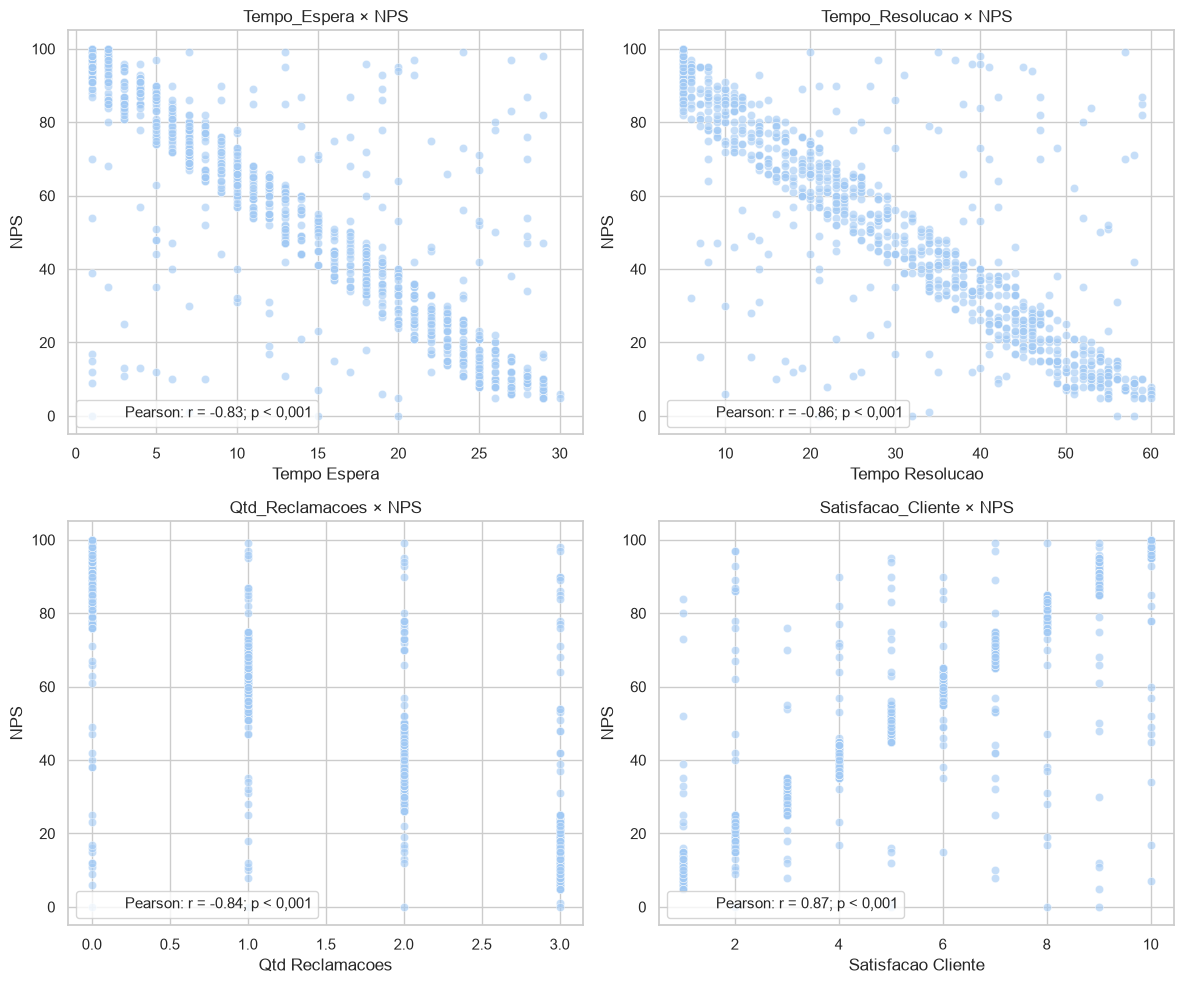

-------------- Testes de Correlação de Pearson com o NPS --------------
Tempo_Espera: r = -0.832, p-valor = 4.707e-258, n = 1000
Tempo_Resolucao: r = -0.856, p-valor = 7.521e-288, n = 1000
Qtd_Reclamacoes: r = -0.837, p-valor = 1.084e-263, n = 1000
Satisfacao_Cliente: r = 0.868, p-valor = 1.41e-305, n = 1000


In [6]:
# Variáveis numéricas que serão comparadas com o NPS
variaveis = [
    "Tempo_Espera",
    "Tempo_Resolucao",
    "Qtd_Reclamacoes",
    "Satisfacao_Cliente",
]

# Formatar o p-valor para exibição
def formatar_p_valor(p):
    return "p < 0,001" if p < 0.001 else f"p = {p:.3f}".replace(".", ",")

# Criar um gráfico para cada variável
n_colunas = 2
n_linhas = (len(variaveis) + n_colunas - 1) // n_colunas

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(12, 5 * n_linhas),
)
axes = np.array(axes).flatten()

resultados = []

for ax, variavel in zip(axes, variaveis):
    # Remover linhas sem dados nas variáveis do teste
    pares_validos = df[[variavel, "Media_NPS"]].dropna()

    # Calcular correlação de Pearson e p-valor
    r, p_valor = pearsonr(
        pares_validos[variavel],
        pares_validos["Media_NPS"],
    )

    resultados.append((variavel, r, p_valor, len(pares_validos)))

    # Gráfico de dispersão
    sns.scatterplot(
        data=pares_validos,
        x=variavel,
        y="Media_NPS",
        alpha=0.6,
        ax=ax,
    )

    ax.set_title(f"{variavel} × NPS")
    ax.set_xlabel(variavel.replace("_", " "))
    ax.set_ylabel("NPS")

    legenda = Line2D(
        [],
        [],
        linestyle="none",
        label=f"Pearson: r = {r:.2f}; {formatar_p_valor(p_valor)}",
    )
    ax.legend(handles=[legenda], loc="lower left")

# Remover eixos vazios quando o número de gráficos for ímpar
for ax in axes[len(variaveis):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

# Exibir os resultados dos testes
print("-------------- Testes de Correlação de Pearson com o NPS --------------")

for variavel, r, p_valor, n in resultados:
    print(
        f"{variavel}: r = {r:.3f}, "
        f"p-valor = {p_valor:.4g}, n = {n}"
    )

### Q3 - O sentimento expresso pelos clientes nos feedbacks pode ser um indicador confiável da resolução de problemas?

Para responder essa questão, será realizado uma **análise de associação** entre a variável `Problema_Solucionado` que indicia se o problema do cliente foi ou não resolvido e a variável `Feedback_Sentimento`. Para essa análise, utilizou-se o information value (IV) para medir o poder de separação da variável de sentimento com relação a solução de problemas.

O **Information Value (IV)** atua como uma medida exploratória para comparar o poder de separação de cada variável em relação à resposta. Para cada categoria *i* da variável, calcula-se o WoE (***Weight of Evidence***) e a contribuição parcial ao IV. Ele é calculado a partir de:

$$
\mathrm{IV} = \sum_i \left(\%\,\mathrm{Não}_i - \%\,\mathrm{Sim}_i\right)\times \mathrm{WoE}_i
$$

Nesta análise, o WoE é calculado como o logaritmo natural da proporção entre clientes que não compraram o produto (**%NonEvent**) em relação à proporção dos que compraram (**%Event**), em cada categoria:

$$
\mathrm{WoE}_i = \ln\left(\frac{\%\,\mathrm{Não}_i}{\%\,\mathrm{Sim}_i}\right)
$$

onde:
- **% Nãoᵢ**: proporção dos clientes que **não tiveram o seu problema solucionado** e pertencem à categoria *i*.
- **% Simᵢ**: proporção dos clientes que **tiveram o seu problema solucionado** o produto e pertencem à categoria *i*.

Os valores de IV foram interpretados de forma aproximada segundo as faixas abaixo:
| Faixa de IV | Interpretação |
|:---:|:---:|
| < 0,02 | Muito fraco |
| Entre 0,02 e 0,10 | Fraco |
| Entre 0,10 e 0,30 | Médio |
| Entre 0,30 e 0,50 | Forte |
| Maior que 0,50 | Suspeito ou muito alto; recomenda-se verificar |


Para realizar os cálculos, importamos a classe **AnaliseIV** do módulo `src/analise_IV.py`. O método `get_iv_list()` retorna as variáveis ordenadas por IV decrescente, acompanhadas de sua classificação. Já o método `get_freq_table()` apresenta, para cada categoria da variável, as frequências observadas, os percentuais de “Não” e “Sim”, os valores de WoE e as contribuições parciais ao IV. Assim, podemos comparar as variáveis e examinar como cada categoria contribui para sua capacidade de separação.

> **Nota 1:**
> Quando uma categoria não possui observações em uma das classes (“Sim” ou “Não”), a implementação adiciona uma **correção de 0,5** às contagens dessa categoria para calcular o WoE e o IV. As frequências e os percentuais apresentados na tabela permanecem baseados nas contagens observadas.

> **Nota 2:**
> É fundamental levar em consideração o **número de observações em cada categoria**, pois isso resulta em uma maior ou menor **confiança na estimativa da frenquência** obtida (teoria frequentista).

In [7]:
from src.analise_IV import AnaliseIV

use_cols = ['Feedback_Sentimento']

analise = AnaliseIV(
    df=df,
    use_cols=use_cols,
    target='Problema_Solucionado'
)

display(analise.get_freq_table('Feedback_Sentimento'))

col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
Feedback_Sentimento,,,,,,,,,
Negativo,165,159,324,32.4,32.54,32.25,49.07,0.0090,0.0000
Neutro,162,174,336,33.6,31.95,35.29,51.79,-0.0995,0.0033
Positivo,180,160,340,34.0,35.50,32.45,47.06,0.0898,0.0027
Total,507,493,1000,100.0,100.00,100.00,49.30,NaN,0.0061


Antes de escrever as conclusões é importante explicar uma diferença entre `% Sim` e `Taxa Evento` contidas nas tabelas de frequências geradas pelo `get_freq_table()`.

- **Percentual de Eventos (% Sim)**: Representa a participação de cada categoria no total de eventos observados na base de dados.

    $$
    \%Sim_i = \frac{Sim_i}{\sum_i Sim_i} \times 100
    $$

    Responde:***"Do total de clientes que conseguiram resolver o seu problema, qual percentual pertence a essa categoria?"***

- **Taxa de Eventos**: Representa a proporção de eventos observados dentro de uma determinada categoria.

    $$
    TaxaEvento_i = \frac{Sim_i}{Total_i} \times 100
    $$

    Responde: ***"Entre os clientes desta categoria, qual percentual resolveu o seu problema?"***

### Q4 - Será que clientes que esperam menos tempo têm mais chances de ter seus problemas resolvidos?

In [8]:
# Separando as Faixas de Tempo de Espera de 5 em 5 minutos
df['Faixa_Tempo_Espera'] = pd.cut(
    df['Tempo_Espera'],
    bins=[0, 5, 10, 15, 20, np.inf],
    labels=['Até 5 min', 'Entre 5-10 min', 'Entre 10-15 min', 'Entre 15-20 min', '20+ min'],
    right=False
)

# Analisando a variável Faixa_Tempo_Espera em relação à variável Problema_Solucionado
use_cols = ['Faixa_Tempo_Espera']
analise_tempo_espera = AnaliseIV(
    df=df,
    use_cols=use_cols,
    target='Problema_Solucionado'
)

display(analise_tempo_espera.get_freq_table('Faixa_Tempo_Espera'))

col_0,Não,Sim,Total,Freq Rel (%),% Não,% Sim,Taxa Evento (%),WoE,IV Parcial
Faixa_Tempo_Espera,,,,,,,,,
Até 5 min,63,155,218,21.8,12.43,31.44,71.10,-0.9283,0.1765
Entre 5-10 min,60,107,167,16.7,11.83,21.70,64.07,-0.6065,0.0599
Entre 10-15 min,80,85,165,16.5,15.78,17.24,51.52,-0.0886,0.0013
Entre 15-20 min,107,41,148,14.8,21.10,8.32,27.70,0.9313,0.1191
20+ min,197,105,302,30.2,38.86,21.30,34.77,0.6012,0.1056
Total,507,493,1000,100.0,100.00,100.00,49.30,NaN,0.4623


### Q5 - Os clientes que deixam feedbacks positivos realmente tendem a dar notas mais altas no NPS? Ou essa relação não é tão forte?

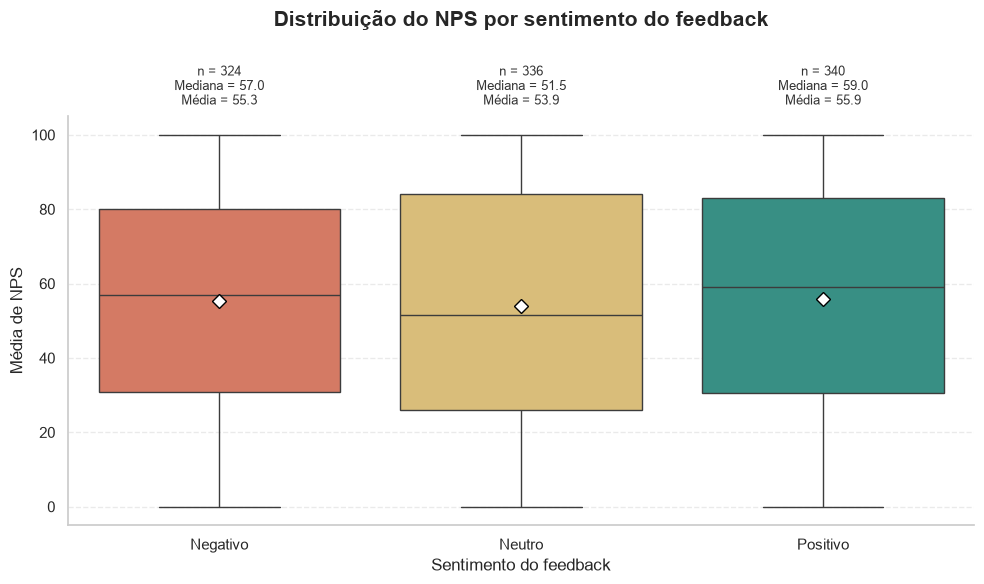

In [9]:
ordem = ["Negativo", "Neutro", "Positivo"]
cores = {
    "Negativo": "#E76F51",
    "Neutro": "#E9C46A",
    "Positivo": "#2A9D8F",
}

# Remove linhas sem dados nas duas variáveis
dados_plot = df[["Feedback_Sentimento", "Media_NPS"]].dropna()

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=dados_plot,
    x="Feedback_Sentimento",
    y="Media_NPS",
    hue="Feedback_Sentimento",
    order=ordem,
    hue_order=ordem,
    palette=cores,
    legend=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    ax=ax,
)

# Anota mediana, média e quantidade acima de cada caixa
for posicao, sentimento in enumerate(ordem):
    grupo = dados_plot.loc[
        dados_plot["Feedback_Sentimento"] == sentimento,
        "Media_NPS",
    ]

    if grupo.empty:
        continue

    mediana = grupo.median()
    media = grupo.mean()
    quantidade = grupo.count()

    ax.annotate(
        f"n = {quantidade}\nMediana = {mediana:.1f}\nMédia = {media:.1f}",
        xy=(posicao, 1.02),
        xycoords=("data", "axes fraction"),
        ha="center",
        va="bottom",
        fontsize=9,
        color="#333333",
    )

ax.set_title(
    "Distribuição do NPS por sentimento do feedback",
    fontsize=15,
    fontweight="bold",
    pad=65,
)
ax.set_xlabel("Sentimento do feedback")
ax.set_ylabel("Média de NPS")
ax.grid(axis="y", linestyle="--", alpha=0.4)
sns.despine()

plt.tight_layout()
plt.show()

In [10]:
dados_eta = df[["Feedback_Sentimento", "Media_NPS"]].dropna()

media_geral = dados_eta["Media_NPS"].mean()

# Soma dos quadrados entre os grupos
sq_entre = sum(
    len(grupo) * (grupo["Media_NPS"].mean() - media_geral) ** 2
    for _, grupo in dados_eta.groupby("Feedback_Sentimento", observed=True)
)

# Soma total dos quadrados
sq_total = ((dados_eta["Media_NPS"] - media_geral) ** 2).sum()

eta_quadrado = sq_entre / sq_total

print(f"η² = {eta_quadrado:.4f}")
print(f"Variação associada ao sentimento = {eta_quadrado:.4%}")

η² = 0.0008
Variação associada ao sentimento = 0.0814%


### Q6 - Qual é o tempo médio de espera até o atendimento e ele é compatível com a meta?

O tempo de espera até o atendimento pode influenciar a percepção do cliente sobre a qualidade do suporte. A AtendeBem quer avaliar se o tempo médio observado está alinhado ao benchmark de **menos de 15 minutos**.

Para responder essa pergunta, precisamos construir um **intervalor de confiança**, pois estamos lidando com uma amostra de clientes. Como o desvio-padrão populacional é desconhecido, será utilizada a distribuição *t* de Student:

$$
\
IC_{95\%} =
\bar{x} \pm t_{0{,}975;\,n-1}
\left(\frac{s}{\sqrt{n}}\right)
\
$$

Em que:
- x̄ representa a média amostral do tempo de espera;
- s representa o desvio-padrão amostral;
- n representa o número de registros;
- t(0,975; n − 1) representa o valor crítico da distribuição t para 95% de confiança e n − 1 graus de liberdade;
- s / √n representa o erro-padrão da média.

Considerando que a amostra seja representativa, o intervalo de confiança possibilita estimar a incerteza amostral introduzida no processo de amostragem.

In [11]:
tempo_espera = df["Tempo_Espera"]

# Estatísticas amostrais
n = len(tempo_espera)
media = tempo_espera.mean()
desvio_padrao = tempo_espera.std(ddof=1)

# Intervalo de confiança de 95% usando a distribuição t de Student
erro_padrao = desvio_padrao / (n ** 0.5)
valor_critico = t.ppf(0.975, df=n - 1)
margem_erro = valor_critico * erro_padrao

limite_inferior = media - margem_erro
limite_superior = media + margem_erro

print(f"Tamanho da amostra: {n}")
print(f"Média Amostral: {media:.2f} minutos")
print(f"Desvio-padrão amostral: {desvio_padrao:.2f} minutos")
print(f"Intervalo de confiança de 95%: "
      f"[{limite_inferior:.2f}, {limite_superior:.2f}] minutos")
print(f"Margem de Erro: {margem_erro:.2f} minutos")

Tamanho da amostra: 1000
Média Amostral: 13.36 minutos
Desvio-padrão amostral: 8.78 minutos
Intervalo de confiança de 95%: [12.81, 13.90] minutos
Margem de Erro: 0.54 minutos


### Q7- Qual é a Taxa de Resolução de Problemas apresentada pela amostra? Ela supera a taxa histórica de 55%?


Para estimar o intervalo da proporção, utilizaremos o **intervalo de Wilson**:

$$
\frac{
\hat{p} + \frac{z^2}{2n}
\pm
z\sqrt{\frac{\hat{p}(1-\hat{p})}{n}+\frac{z^2}{4n^2}}
}{
1+\frac{z^2}{n}
}
$$

em que:

- $n$ é o número de clientes observados;
- $x$ é o número de clientes que compraram o título;
- $\hat{p} = x/n$ é a proporção observada;
- $z$ é o quantil da distribuição normal padrão correspondente ao nível de confiança. Para 95% de confiança, $z \approx 1{,}96$.

Para comparação, também calcularemos o **intervalo binomial exato de Clopper–Pearson**, construído para estimar uma proporção binomial. Além disso, testaremos uma aproximação baseada na distribuição *t* de Student. Como a variável de compra é binária, sua proporção corresponde à média dos valores codificados como 0 e 1. Com uma amostra grande como esta, o intervalo *t* pode servir como comparação; ainda assim, ele não considera diretamente a natureza discreta e limitada da proporção. Por isso, compararemos seus resultados com os métodos próprios para proporções.

In [12]:
df["Problema_Solucionado"].value_counts()

Problema_Solucionado
Não    507
Sim    493
Name: count, dtype: int64

In [14]:
# Dados observados
problemas_solucionados = 493
n = 1000
nivel_confianca = 0.95

p_hat = problemas_solucionados / n
alpha = 1 - nivel_confianca
z = 1.959963984540054  # quantil normal para 95% de confiança


# Intervalo de Wilson
denominador = 1 + z**2 / n
centro = (p_hat + z**2 / (2 * n)) / denominador
margem = (
    z
    * sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))
    / denominador
)
wilson = (centro - margem, centro + margem)


# Intervalo binomial exato de Clopper–Pearson
clopper_pearson = (
    beta.ppf(alpha / 2, problemas_solucionados, n - problemas_solucionados + 1),
    beta.ppf(1 - alpha / 2, problemas_solucionados + 1, n - problemas_solucionados),
)


# Intervalo t de Student aplicado aos indicadores binários (0 = não comprou, 1 = comprou)
gl = n - 1
desvio_padrao = sqrt(n / (n - 1) * p_hat * (1 - p_hat))
erro_padrao = desvio_padrao / sqrt(n)
t_critico = t.ppf(1 - alpha / 2, df=gl)
margem_t = t_critico * erro_padrao
intervalo_t = (p_hat - margem_t, p_hat + margem_t)


# Exibição dos resultados
intervalos = {
    "Wilson": wilson,
    "Clopper–Pearson": clopper_pearson,
    "t de Student": intervalo_t,
}

print(f"Clientes analisados: {n:,}".replace(",", "."))
print(f"problemas_solucionados: {problemas_solucionados:,}".replace(",", "."))
print(f"Proporção observada: {p_hat:.2%}")
print(f"Nível de confiança: {nivel_confianca:.0%}\n")

print(f"{'Método':<22} {'Limite inferior':>17} {'Limite superior':>17} {'Largura':>12}")
print("-" * 72)

for metodo, (inferior, superior) in intervalos.items():
    print(
        f"{metodo:<22} "
        f"{inferior:>16.2%} "
        f"{superior:>16.2%} "
        f"{superior - inferior:>11.2%}"
    )

Clientes analisados: 1.000
problemas_solucionados: 493
Proporção observada: 49.30%
Nível de confiança: 95%

Método                   Limite inferior   Limite superior      Largura
------------------------------------------------------------------------
Wilson                           46.21%           52.40%       6.19%
Clopper–Pearson                  46.16%           52.45%       6.29%
t de Student                     46.20%           52.40%       6.21%


# 3. Indo além... Outras Análises

### Qual Canal de Atendimento tende a ser mais rápido em responder?

,Canal,n,Média amostral,IC 95% — limite inferior,IC 95% — limite superior
0,Redes Sociais,213,12.54,11.32,13.76
1,Telefone,185,13.02,11.77,14.28
2,E-mail,201,13.29,12.08,14.51
3,Chat,225,13.59,12.46,14.72
4,WhatsApp,176,14.47,13.14,15.79


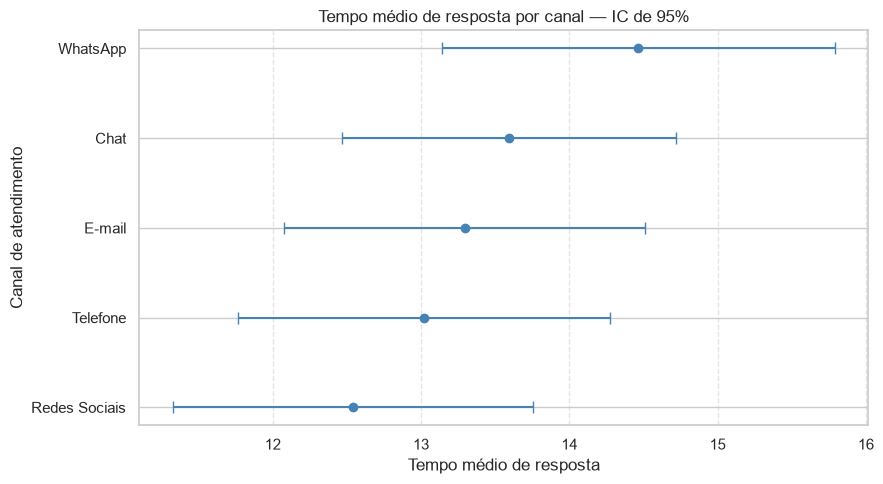

In [19]:
# Ajustar para os nomes das colunas da sua base
coluna_canal = "Canal_Atendimento"
coluna_tempo = "Tempo_Espera"

# Remover registros sem canal ou tempo de resposta
dados = df[[coluna_canal, coluna_tempo]]

resultados = []

for canal, grupo in dados.groupby(coluna_canal)[coluna_tempo]:
    n = grupo.count()
    media = grupo.mean()  # Estimativa pontual
    desvio_padrao = grupo.std(ddof=1)

    # Calcular o intervalo de confiança de 95% para a média
    erro_padrao = desvio_padrao / (n ** 0.5)
    valor_critico = t.ppf(0.975, df=n - 1)

    limite_inferior = media - valor_critico * erro_padrao
    limite_superior = media + valor_critico * erro_padrao

    resultados.append({
        "Canal": canal,
        "n": n,
        "Média amostral": media,
        "IC 95% — limite inferior": limite_inferior,
        "IC 95% — limite superior": limite_superior,
    })

# Apresentar a tabela com a estimativa pontual e o intervalo de confiança
tabela_resultados = (
    pd.DataFrame(resultados)
    .sort_values("Média amostral")
    .reset_index(drop=True)
)

display(tabela_resultados.round(2))

# Visualizar as estimativas pontuais e intervalares
plt.figure(figsize=(9, 5))

for _, linha in tabela_resultados.iterrows():
    media = linha["Média amostral"]
    erro_inferior = media - linha["IC 95% — limite inferior"]
    erro_superior = linha["IC 95% — limite superior"] - media

    plt.errorbar(
        x=media,
        y=linha["Canal"],
        xerr=[[erro_inferior], [erro_superior]],
        fmt="o",
        capsize=4,
        color="steelblue",
    )

plt.xlabel("Tempo médio de resposta")
plt.ylabel("Canal de atendimento")
plt.title("Tempo médio de resposta por canal — IC de 95%")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [21]:
import pandas as pd
from scipy import stats

# Ajustar para os nomes das colunas da sua base
coluna_canal = "Canal_Atendimento"
coluna_tempo = "Tempo_Espera"

# Manter registros com canal e tempo de resposta disponíveis
dados = df[[coluna_canal, coluna_tempo]].dropna()

# Organizar os tempos de resposta por canal
grupos = {
    canal: grupo[coluna_tempo].to_numpy()
    for canal, grupo in dados.groupby(coluna_canal)
}

# Etapa 1: testar se há diferença global entre as médias
resultado_global = stats.f_oneway(
    *grupos.values(),
    equal_var=False  # ANOVA de Welch
)

print("ANOVA de Welch")
print(f"Estatística F: {resultado_global.statistic:.3f}")
print(f"Valor-p: {resultado_global.pvalue:.4f}")

# Etapa 2: comparar todos os pares de canais
# equal_var=False aplica o procedimento de Games–Howell
resultado_pares = stats.tukey_hsd(
    *grupos.values(),
    equal_var=False
)

intervalos = resultado_pares.confidence_interval(
    confidence_level=0.95
)

nomes_canais = list(grupos.keys())
comparacoes = []

for i in range(len(nomes_canais)):
    for j in range(i + 1, len(nomes_canais)):
        comparacoes.append({
            "Canal A": nomes_canais[i],
            "Canal B": nomes_canais[j],
            "Diferença média (A - B)": resultado_pares.statistic[i, j],
            "IC 95% da diferença — limite inferior": intervalos.low[i, j],
            "IC 95% da diferença — limite superior": intervalos.high[i, j],
            "Valor-p ajustado": resultado_pares.pvalue[i, j],
        })

tabela_comparacoes = pd.DataFrame(comparacoes)

display(tabela_comparacoes.round(3))

ANOVA de Welch
Estatística F: 1.227
Valor-p: 0.2983


,Canal A,Canal B,Diferença média (A - B),IC 95% da diferença — limite inferior,IC 95% da diferença — limite superior,Valor-p ajustado
0,Chat,E-mail,0.298,-2.006,2.601,0.997
1,Chat,Redes Sociais,1.051,-1.252,3.355,0.722
2,Chat,Telefone,0.569,-1.774,2.913,0.964
3,Chat,WhatsApp,-0.875,-3.295,1.545,0.859
4,E-mail,Redes Sociais,0.754,-1.636,3.143,0.910
5,E-mail,Telefone,0.272,-2.156,2.700,0.998
6,E-mail,WhatsApp,-1.172,-3.674,1.329,0.701
7,Redes Sociais,Telefone,-0.482,-2.910,1.947,0.983
8,Redes Sociais,WhatsApp,-1.926,-4.428,0.576,0.218
9,Telefone,WhatsApp,-1.444,-3.983,1.094,0.524


### Qual tipo de problema estão tendo mais dificuldade de resolver?

,Total de casos,Não solucionados,Proporção não solucionada,IC 95% inferior,IC 95% superior
Tipo_Problema,,,,,
Dúvida,249,133,53.4%,47.2%,59.5%
Cobrança,261,136,52.1%,46.1%,58.1%
Produto Defeituoso,231,117,50.6%,44.2%,57.0%
Atendimento Ruim,259,121,46.7%,40.7%,52.8%


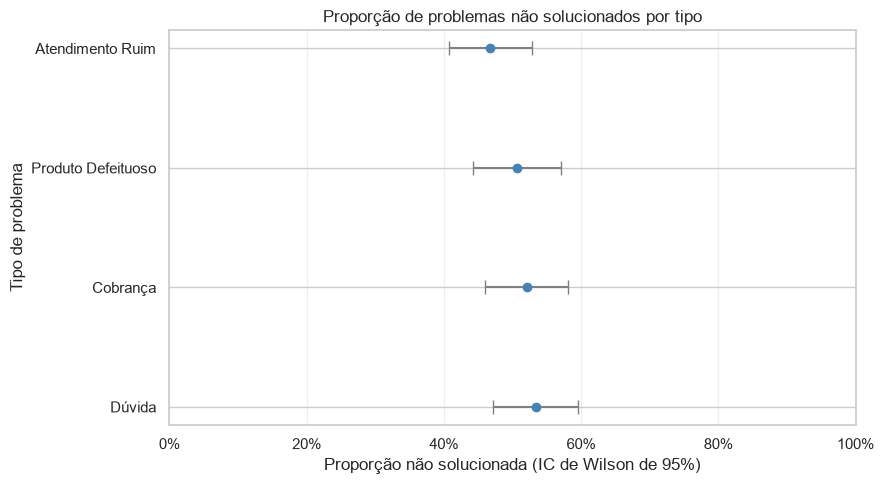

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Uma linha por tipo de problema, com contagem e proporção de casos não solucionados
dados = df[["Tipo_Problema", "Problema_Solucionado"]].dropna().copy()
dados["Nao_Solucionado"] = (
    dados["Problema_Solucionado"].str.strip().str.casefold() == "não"
).astype(int)

resumo = (
    dados.groupby("Tipo_Problema", observed=True)["Nao_Solucionado"]
    .agg(n="count", casos_nao_solucionados="sum")
)

resumo["proporcao"] = resumo["casos_nao_solucionados"] / resumo["n"]

# Intervalo de confiança de Wilson (95%)
z = norm.ppf(0.975)
p = resumo["proporcao"]
n = resumo["n"]

denominador = 1 + z**2 / n
centro = (p + z**2 / (2 * n)) / denominador
margem = (
    z
    * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n)
    / denominador
)

resumo["ic95_inferior"] = centro - margem
resumo["ic95_superior"] = centro + margem

# Ordena do maior para o menor percentual não solucionado
resumo = resumo.sort_values("proporcao", ascending=False)

# Tabela
tabela = resumo.rename(columns={
    "n": "Total de casos",
    "casos_nao_solucionados": "Não solucionados",
    "proporcao": "Proporção não solucionada",
    "ic95_inferior": "IC 95% inferior",
    "ic95_superior": "IC 95% superior",
}).copy()

for coluna in [
    "Proporção não solucionada",
    "IC 95% inferior",
    "IC 95% superior",
]:
    tabela[coluna] = tabela[coluna].map(lambda x: f"{x:.1%}")

display(tabela)

# Gráfico: estimativa pontual e intervalo de Wilson
fig, ax = plt.subplots(figsize=(9, 5))

x = resumo["proporcao"].to_numpy()
limite_inferior = resumo["ic95_inferior"].to_numpy()
limite_superior = resumo["ic95_superior"].to_numpy()

ax.errorbar(
    x,
    resumo.index,
    xerr=[
        x - limite_inferior,
        limite_superior - x,
    ],
    fmt="o",
    capsize=5,
    color="steelblue",
    ecolor="gray",
)

ax.set(
    title="Proporção de problemas não solucionados por tipo",
    xlabel="Proporção não solucionada (IC de Wilson de 95%)",
    ylabel="Tipo de problema",
    xlim=(0, 1),
)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda valor, _: f"{valor:.0%}"))
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
from itertools import combinations

import pandas as pd
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_chisquare


# Tabela de frequências: linhas = tipo; colunas = resultado
contingencia = pd.crosstab(
    dados["Tipo_Problema"],
    dados["Problema_Solucionado"].str.strip().str.capitalize()
)

# Garanta que as duas colunas estejam presentes
contingencia = contingencia.reindex(columns=["Não", "Sim"], fill_value=0)

# 1) Teste global
resultado_global = chi2_contingency(contingencia, correction=False)

print(f"Qui-quadrado = {resultado_global.statistic:.3f}")
print(f"Graus de liberdade = {resultado_global.dof}")
print(f"p-valor = {resultado_global.pvalue:.4f}")
print("\nFrequências esperadas:")
display(pd.DataFrame(
    resultado_global.expected_freq,
    index=contingencia.index,
    columns=contingencia.columns
).round(1))

# 2) Comparações par a par, somente se o teste global for significativo
if resultado_global.pvalue < 0.05:
    # A contagem de "Não" é o número de casos não solucionados
    nao = contingencia["Não"]
    totais = contingencia.sum(axis=1)

    comparacoes = []

    for tipo_a, tipo_b in combinations(contingencia.index, 2):
        # Testa se as duas categorias têm a mesma proporção de "Não"
        _, p_valor = proportions_chisquare(
            count=[nao[tipo_a], nao[tipo_b]],
            nobs=[totais[tipo_a], totais[tipo_b]]
        )

        comparacoes.append({
            "Tipo A": tipo_a,
            "Tipo B": tipo_b,
            "Proporção A": nao[tipo_a] / totais[tipo_a],
            "Proporção B": nao[tipo_b] / totais[tipo_b],
            "p-valor": p_valor,
        })

    pares = pd.DataFrame(comparacoes)

    # Correção de Holm para as comparações múltiplas
    ordem = pares["p-valor"].sort_values().index
    p_ordenados = pares.loc[ordem, "p-valor"].to_numpy()
    m = len(p_ordenados)

    p_ajustados_ordenados = [
        min(1, (m - i) * p)
        for i, p in enumerate(p_ordenados)
    ]

    # Garante que os p-valores ajustados não diminuam na ordem crescente
    for i in range(1, m):
        p_ajustados_ordenados[i] = max(
            p_ajustados_ordenados[i],
            p_ajustados_ordenados[i - 1]
        )

    pares["p-valor ajustado (Holm)"] = float("nan")
    pares.loc[ordem, "p-valor ajustado (Holm)"] = p_ajustados_ordenados
    pares["Diferença significativa (5%)"] = (
        pares["p-valor ajustado (Holm)"] < 0.05
    )

    display(pares.sort_values("p-valor ajustado (Holm)"))
else:
    print(
        "\nO teste global não foi significativo a 5%; "
        "não há evidência suficiente para concluir que as proporções "
        "diferem entre os tipos."
    )

Qui-quadrado = 2.584
Graus de liberdade = 3
p-valor = 0.4604

Frequências esperadas:


Problema_Solucionado,Não,Sim
Tipo_Problema,,
Atendimento Ruim,131.3,127.7
Cobrança,132.3,128.7
Dúvida,126.2,122.8
Produto Defeituoso,117.1,113.9



O teste global não foi significativo a 5%; não há evidência suficiente para concluir que as proporções diferem entre os tipos.


# 4. Plano de Recomendação

# 5. Como aprofundar as Análises

# 6. Considerações Finais